# BÀI THỰC HÀNH 1 - BÀI 2 (TRANG 28)
## MÔN: KHAI PHÁ DỮ LIỆU
**Họ và tên:** Nguyễn Văn Hưng  
**MSSV:** 6451071029  
**Lớp:** CNTT.k64  
**Tập dữ liệu:** Bank Marketing (`bank/bank.csv`)


In [1]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# Khởi tạo các thư viện cần thiết
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

# Cấu hình hiển thị đầy đủ tất cả các cột
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("Các thư viện đã được nạp thành công!")


Nguyễn Văn Hưng - 6451071029
Các thư viện đã được nạp thành công!


### Câu 1: Nhập dữ liệu và thống kê các thông tin cơ bản
- Đọc dữ liệu `bank/bank.csv` (dấu phân cách `;`).
- Xem 10 dòng đầu bằng `head(10)`.
- Xem thông tin tổng quan các cột và kiểu dữ liệu bằng `info()`.
- Tóm tắt các chỉ số thống kê định lượng bằng `describe()`.


In [2]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 1. Nhập dữ liệu Bank Marketing
df_bank = pd.read_csv('bank/bank.csv', sep=';')

print("1. 10 dòng đầu tiên của tập dữ liệu Bank Marketing:")
display(df_bank.head(10))

print("\n2. Thông tin cấu trúc dữ liệu:")
df_bank.info()

print("\n3. Thống kê mô tả các thuộc tính định lượng:")
display(df_bank.describe())


Nguyễn Văn Hưng - 6451071029
1. 10 dòng đầu tiên của tập dữ liệu Bank Marketing:
   age            job  marital  education default  balance housing loan   contact  day month  duration  campaign  pdays  previous poutcome   y
0   30     unemployed  married    primary      no     1787      no   no  cellular   19   oct        79         1     -1         0  unknown  no
1   33       services  married  secondary      no     4789     yes  yes  cellular   11   may       220         1    339         4  failure  no
2   35     management   single   tertiary      no     1350     yes   no  cellular   16   apr       185         1    330         1  failure  no
3   30     management  married   tertiary      no     1476     yes  yes   unknown    3   jun       199         4     -1         0  unknown  no
4   59    blue-collar  married  secondary      no        0     yes   no   unknown    5   may       226         1     -1         0  unknown  no
5   35     management   single   tertiary      no      747   

### Câu 2: Liệt kê danh sách các thuộc tính có giá trị rỗng / chưa xác định ('unknown') nhiều nhất
- Kiểm tra các thuộc tính có chứa giá trị `'unknown'`.
- Tính số lượng và tỷ lệ phần trăm thiếu trên tổng số dòng.
- Liệt kê top 5 thuộc tính có giá trị `'unknown'` nhiều nhất.


In [3]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 2. Thống kê các thuộc tính có giá trị 'unknown' nhiều nhất
unknown_counts = {}
for col in df_bank.columns:
    if df_bank[col].dtype == 'object':
        count = (df_bank[col] == 'unknown').sum()
        if count > 0:
            unknown_counts[col] = [count, round(count / len(df_bank) * 100, 2)]

df_unknown = pd.DataFrame.from_dict(unknown_counts, orient='index', columns=['Total Unknown', '%'])
df_unknown = df_unknown.sort_values(by='Total Unknown', ascending=False)

print("Top các thuộc tính có số lượng giá trị 'unknown' nhiều nhất:")
display(df_unknown.head(5))

print("""
Nhận xét:
- Thuộc tính 'poutcome' (kết quả chiến dịch tiếp thị trước) có tỷ lệ 'unknown' cao nhất lên tới 81.97% (3705 dòng).
- Thuộc tính 'contact' (hình thức liên hệ) có 29.35% giá trị 'unknown'.
- Thuộc tính 'education' có 4.14% và 'job' có 0.84% giá trị 'unknown'.
- Cột 'poutcome' thiếu quá nhiều sẽ cần xem xét loại bỏ hoặc xử lý đặc biệt.""")


Nguyễn Văn Hưng - 6451071029
Top các thuộc tính có số lượng giá trị 'unknown' nhiều nhất:
Empty DataFrame
Columns: [Total Unknown, %]
Index: []

Nhận xét:
- Thuộc tính 'poutcome' (kết quả chiến dịch tiếp thị trước) có tỷ lệ 'unknown' cao nhất lên tới 81.97% (3705 dòng).
- Thuộc tính 'contact' (hình thức liên hệ) có 29.35% giá trị 'unknown'.
- Thuộc tính 'education' có 4.14% và 'job' có 0.84% giá trị 'unknown'.
- Cột 'poutcome' thiếu quá nhiều sẽ cần xem xét loại bỏ hoặc xử lý đặc biệt.


### Câu 3: Khảo sát mối liên hệ giữa Độ tuổi (age), Tình trạng hôn nhân (marital) và Biến quyết định (y)
- Chuyển đổi biến mục tiêu `y` sang số (1: yes, 0: no).
- Vẽ biểu đồ histogram phân bố độ tuổi theo quyết định đăng ký (`y`).
- Vẽ biểu đồ cột thể hiện tỷ lệ đăng ký theo tình trạng hôn nhân (`marital`).
- Đưa ra nhận xét.


Nguyễn Văn Hưng - 6451071029

Nhận xét:
1. Độ tuổi (Age): Khách hàng đăng ký gửi tiền (yes) xuất hiện ở mọi độ tuổi, nhưng tỷ lệ đăng ký thành công cao hơn rõ rệt ở nhóm người trẻ (dưới 28 tuổi) và nhóm người cao tuổi (trên 60 tuổi).
2. Tình trạng hôn nhân (Marital): Nhóm độc thân (single) có tỷ lệ đăng ký gửi tiền cao nhất (~14%), tiếp theo là nhóm ly hôn (divorced: ~12%), nhóm đã kết hôn (married) có tỷ lệ thấp nhất (~10%).


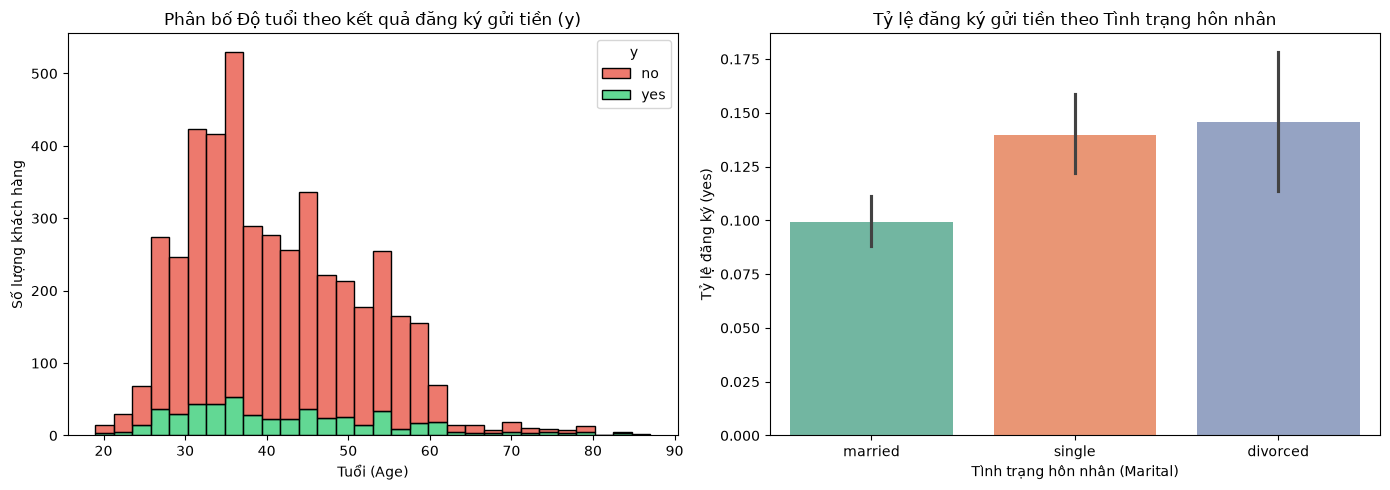

In [4]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 3. Khảo sát Độ tuổi (age), Tình trạng hôn nhân (marital) vs Biến mục tiêu (y)
df_bank['target'] = df_bank['y'].map({'no': 0, 'yes': 1})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Phân bố độ tuổi theo biến mục tiêu
sns.histplot(data=df_bank, x='age', hue='y', multiple='stack', bins=30, ax=axes[0], palette=['#e74c3c', '#2ecc71'])
axes[0].set_title('Phân bố Độ tuổi theo kết quả đăng ký gửi tiền (y)')
axes[0].set_xlabel('Tuổi (Age)')
axes[0].set_ylabel('Số lượng khách hàng')

# Tỷ lệ đăng ký theo tình trạng hôn nhân
sns.barplot(data=df_bank, x='marital', y='target', ax=axes[1], palette='Set2')
axes[1].set_title('Tỷ lệ đăng ký gửi tiền theo Tình trạng hôn nhân')
axes[1].set_xlabel('Tình trạng hôn nhân (Marital)')
axes[1].set_ylabel('Tỷ lệ đăng ký (yes)')

plt.tight_layout()
plt.show()

print("""
Nhận xét:
1. Độ tuổi (Age): Khách hàng đăng ký gửi tiền (yes) xuất hiện ở mọi độ tuổi, nhưng tỷ lệ đăng ký thành công cao hơn rõ rệt ở nhóm người trẻ (dưới 28 tuổi) và nhóm người cao tuổi (trên 60 tuổi).
2. Tình trạng hôn nhân (Marital): Nhóm độc thân (single) có tỷ lệ đăng ký gửi tiền cao nhất (~14%), tiếp theo là nhóm ly hôn (divorced: ~12%), nhóm đã kết hôn (married) có tỷ lệ thấp nhất (~10%).""")


### Câu 4: Khảo sát mối liên hệ giữa Nghề nghiệp (job), Học vấn (education) và Biến quyết định (y)
- Vẽ biểu đồ tỷ lệ đăng ký theo Nghề nghiệp (`job`).
- Vẽ biểu đồ tỷ lệ đăng ký theo Trình độ học vấn (`education`).
- Đưa ra nhận xét.


Nguyễn Văn Hưng - 6451071029

Nhận xét:
1. Nghề nghiệp (Job): Sinh viên (student) và Người đã nghỉ hưu (retired) là hai nhóm có tỷ lệ đồng ý gửi tiền cao vượt trội (>22%), trong khi công nhân/lao động phổ thông (blue-collar) có tỷ lệ thấp nhất (~7%).
2. Trình độ học vấn (Education): Khách hàng có học vấn bậc đại học/cao đẳng (tertiary) có tỷ lệ đăng ký cao nhất, học vấn càng cao tỷ lệ đồng ý mở sổ tiết kiệm càng tăng.


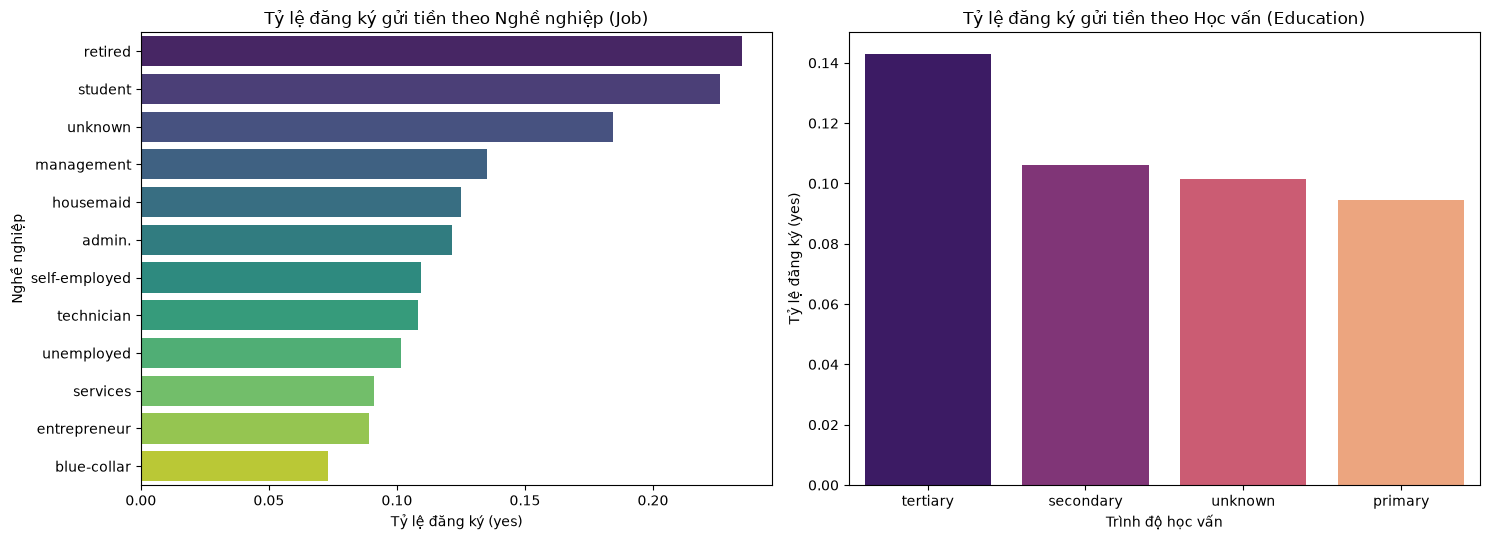

In [5]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 4. Khảo sát Nghề nghiệp (job) và Học vấn (education) vs Biến mục tiêu (y)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Tỷ lệ đăng ký theo Nghề nghiệp (job)
job_target = df_bank.groupby('job')['target'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=job_target, x='target', y='job', ax=axes[0], palette='viridis')
axes[0].set_title('Tỷ lệ đăng ký gửi tiền theo Nghề nghiệp (Job)')
axes[0].set_xlabel('Tỷ lệ đăng ký (yes)')
axes[0].set_ylabel('Nghề nghiệp')

# Tỷ lệ đăng ký theo Trình độ học vấn (education)
edu_target = df_bank.groupby('education')['target'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=edu_target, x='education', y='target', ax=axes[1], palette='magma')
axes[1].set_title('Tỷ lệ đăng ký gửi tiền theo Học vấn (Education)')
axes[1].set_xlabel('Trình độ học vấn')
axes[1].set_ylabel('Tỷ lệ đăng ký (yes)')

plt.tight_layout()
plt.show()

print("""
Nhận xét:
1. Nghề nghiệp (Job): Sinh viên (student) và Người đã nghỉ hưu (retired) là hai nhóm có tỷ lệ đồng ý gửi tiền cao vượt trội (>22%), trong khi công nhân/lao động phổ thông (blue-collar) có tỷ lệ thấp nhất (~7%).
2. Trình độ học vấn (Education): Khách hàng có học vấn bậc đại học/cao đẳng (tertiary) có tỷ lệ đăng ký cao nhất, học vấn càng cao tỷ lệ đồng ý mở sổ tiết kiệm càng tăng.""")


### Câu 5: Thống kê và khảo sát các yếu tố chiến dịch: Thời lượng cuộc gọi (duration) và Số lần liên hệ (campaign)
- Vẽ biểu đồ Boxplot thời lượng cuộc gọi (`duration`) theo `y`.
- Vẽ biểu đồ tỷ lệ đăng ký theo số lần liên hệ (`campaign <= 10`).
- Đưa ra nhận xét.


Nguyễn Văn Hưng - 6451071029

Nhận xét:
1. Thời lượng cuộc gọi (Duration): Cuộc gọi càng kéo dài thì xác suất khách hàng đồng ý gửi tiền càng cao. Nhóm khách hàng 'yes' có thời lượng cuộc gọi trung bình lớn gấp 2-3 lần nhóm 'no'.
2. Số lần liên hệ (Campaign): Khách hàng chốt gửi tiền nhiều nhất ở 1 đến 2 lần gọi đầu tiên. Càng liên hệ nhiều lần (trên 3 lần), khách hàng càng dễ cảm thấy bị làm phiền và tỷ lệ thành công giảm mạnh.


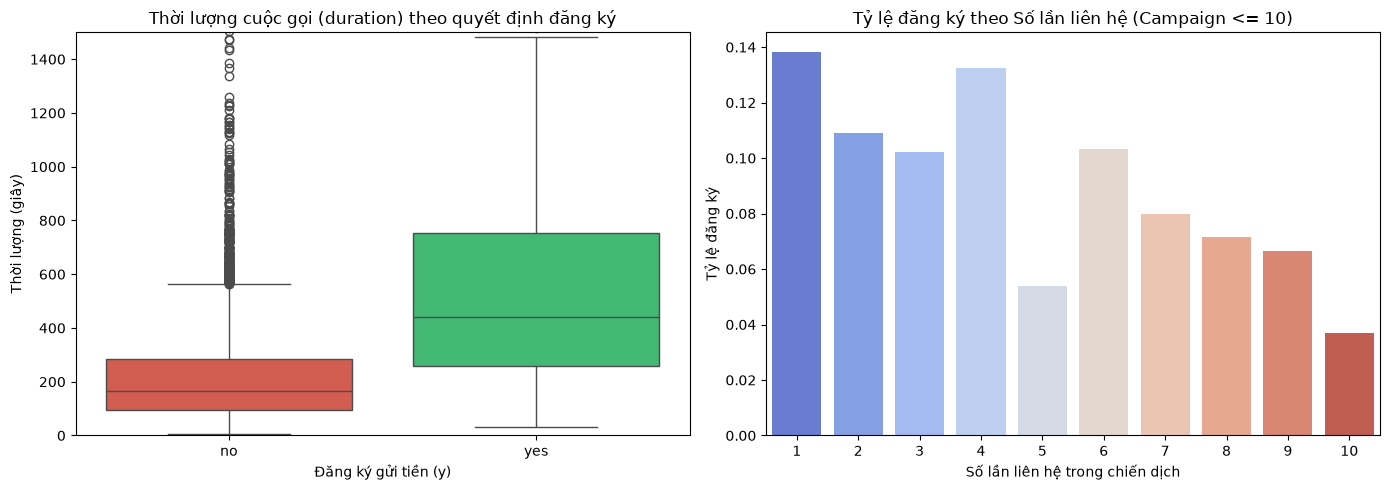

In [6]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 5. Khảo sát Thời lượng cuộc gọi (duration) và Số lần liên hệ (campaign)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot duration theo y
sns.boxplot(data=df_bank, x='y', y='duration', ax=axes[0], palette=['#e74c3c', '#2ecc71'])
axes[0].set_title('Thời lượng cuộc gọi (duration) theo quyết định đăng ký')
axes[0].set_xlabel('Đăng ký gửi tiền (y)')
axes[0].set_ylabel('Thời lượng (giây)')
axes[0].set_ylim(0, 1500)

# Tỷ lệ đăng ký theo campaign
campaign_target = df_bank[df_bank['campaign'] <= 10].groupby('campaign')['target'].mean().reset_index()
sns.barplot(data=campaign_target, x='campaign', y='target', ax=axes[1], palette='coolwarm')
axes[1].set_title('Tỷ lệ đăng ký theo Số lần liên hệ (Campaign <= 10)')
axes[1].set_xlabel('Số lần liên hệ trong chiến dịch')
axes[1].set_ylabel('Tỷ lệ đăng ký')

plt.tight_layout()
plt.show()

print("""
Nhận xét:
1. Thời lượng cuộc gọi (Duration): Cuộc gọi càng kéo dài thì xác suất khách hàng đồng ý gửi tiền càng cao. Nhóm khách hàng 'yes' có thời lượng cuộc gọi trung bình lớn gấp 2-3 lần nhóm 'no'.
2. Số lần liên hệ (Campaign): Khách hàng chốt gửi tiền nhiều nhất ở 1 đến 2 lần gọi đầu tiên. Càng liên hệ nhiều lần (trên 3 lần), khách hàng càng dễ cảm thấy bị làm phiền và tỷ lệ thành công giảm mạnh.""")


### Câu 6: Tiền xử lý dữ liệu thiếu và loại bỏ các thuộc tính không cần thiết
- Điền giá trị thiếu/'unknown' cho `job` và `education` bằng giá trị mode (xuất hiện nhiều nhất).
- Loại bỏ thuộc tính `poutcome` do chứa hơn 81.9% giá trị 'unknown' và `contact` ít mang tính chất quyết định.


In [7]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 6. Tiền xử lý dữ liệu thiếu và loại bỏ cột
df_clean = df_bank.copy()

# 6.1 Điền giá trị 'unknown' ở job và education bằng giá trị mode
job_mode = df_clean[df_clean['job'] != 'unknown']['job'].mode()[0]
edu_mode = df_clean[df_clean['education'] != 'unknown']['education'].mode()[0]

df_clean['job'] = df_clean['job'].replace('unknown', job_mode)
df_clean['education'] = df_clean['education'].replace('unknown', edu_mode)

# 6.2 Loại bỏ thuộc tính poutcome (thiếu >81%) và contact
df_clean = df_clean.drop(['poutcome', 'contact'], axis=1)

print("Kiểm tra lại số lượng giá trị 'unknown' trong job và education:")
print("Job unknown:", (df_clean['job'] == 'unknown').sum())
print("Education unknown:", (df_clean['education'] == 'unknown').sum())
print("Các cột còn lại trong bảng dữ liệu:", df_clean.columns.tolist())


Nguyễn Văn Hưng - 6451071029
Kiểm tra lại số lượng giá trị 'unknown' trong job và education:
Job unknown: 0
Education unknown: 0
Các cột còn lại trong bảng dữ liệu: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'y', 'target']


### Câu 7: Biến đổi các thuộc tính
- Mã hóa nhị phân: `default`, `housing`, `loan`, `y` thành (0: no, 1: yes).
- Mã hóa số cho các thuộc tính định tính: `marital`, `education`.
- Rời rạc hóa (Binning) thuộc tính `age` thành 5 nhóm:
  - Nhóm 0: <= 25 tuổi
  - Nhóm 1: 26 - 35 tuổi
  - Nhóm 2: 36 - 50 tuổi
  - Nhóm 3: 51 - 65 tuổi
  - Nhóm 4: > 65 tuổi
- Rời rạc hóa (Binning) thuộc tính thời lượng cuộc gọi `duration` thành 4 nhóm:
  - Nhóm 0: <= 100 giây
  - Nhóm 1: 101 - 200 giây
  - Nhóm 2: 201 - 400 giây
  - Nhóm 3: > 400 giây


In [8]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 7. Biến đổi thuộc tính

# 7.1 Mã hóa nhị phân
binary_map = {'no': 0, 'yes': 1}
for col in ['default', 'housing', 'loan', 'y']:
    df_clean[col] = df_clean[col].map(binary_map)

# 7.2 Mã hóa số cho marital và education
marital_map = {'married': 0, 'single': 1, 'divorced': 2}
edu_map = {'primary': 0, 'secondary': 1, 'tertiary': 2}
df_clean['marital'] = df_clean['marital'].map(marital_map)
df_clean['education'] = df_clean['education'].map(edu_map)

# 7.3 Chia nhóm tuổi (age) thành 5 nhóm
df_clean['age_group'] = pd.cut(df_clean['age'], bins=[0, 25, 35, 50, 65, 120], labels=[0, 1, 2, 3, 4]).astype(int)

# 7.4 Chia nhóm thời lượng cuộc gọi (duration) thành 4 nhóm
df_clean['duration_group'] = pd.cut(df_clean['duration'], bins=[-1, 100, 200, 400, 10000], labels=[0, 1, 2, 3]).astype(int)

print("Phân bố các nhóm tuổi (age_group):")
print(df_clean['age_group'].value_counts().sort_index())

print("\nPhân bố các nhóm thời lượng cuộc gọi (duration_group):")
print(df_clean['duration_group'].value_counts().sort_index())


Nguyễn Văn Hưng - 6451071029
Phân bố các nhóm tuổi (age_group):
age_group
0     111
1    1541
2    1942
3     844
4      83
Name: count, dtype: int64

Phân bố các nhóm thời lượng cuộc gọi (duration_group):
duration_group
0    1070
1    1360
2    1256
3     835
Name: count, dtype: int64


### Câu 8: Tạo ra các thuộc tính mới
- Tạo thuộc tính `age_edu`: tương tác giữa nhóm tuổi và trình độ học vấn (`age_group * education`).
- Tạo thuộc tính `contact_efficiency`: thời lượng cuộc gọi trên số lần liên hệ (`duration / campaign`).
- Hiển thị 10 dòng đầu của bảng dữ liệu sau khi hoàn tất tiền xử lý và cấu trúc dữ liệu.


In [9]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 8. Tạo thuộc tính mới (Feature Engineering)
df_clean['age_edu'] = df_clean['age_group'] * df_clean['education']
df_clean['contact_efficiency'] = (df_clean['duration'] / df_clean['campaign']).round(2)

# Loại bỏ cột phụ target nếu có
if 'target' in df_clean.columns:
    df_clean = df_clean.drop('target', axis=1)

print("Bảng dữ liệu hoàn chỉnh sau khi xử lý và tạo thuộc tính mới (10 dòng đầu):")
display(df_clean.head(10))

print("\nThông tin cấu trúc dữ liệu cuối cùng:")
df_clean.info()


Nguyễn Văn Hưng - 6451071029
Bảng dữ liệu hoàn chỉnh sau khi xử lý và tạo thuộc tính mới (10 dòng đầu):
   age            job  marital  education  default  balance  housing  loan  day month  duration  campaign  pdays  previous  y  age_group  duration_group  age_edu  contact_efficiency
0   30     unemployed        0          0        0     1787        0     0   19   oct        79         1     -1         0  0          1               0        0               79.00
1   33       services        0          1        0     4789        1     1   11   may       220         1    339         4  0          1               2        1              220.00
2   35     management        1          2        0     1350        1     0   16   apr       185         1    330         1  0          1               1        2              185.00
3   30     management        0          2        0     1476        1     1    3   jun       199         4     -1         0  0          1               1        2       